<a href="https://colab.research.google.com/github/Navoditdev/cnn_hotodg_classifier/blob/main/hotdog_cnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras import layers , datasets, models
import random

import tensorflow_datasets as tfds

In [ ]:
ds , ds_info = tfds.load('food101',as_supervised=True,with_info=True,shuffle_files=True)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/food101/incomplete.MLJVO8_2.0.0/food101-train.tfrecord-[0-9][0-9][0-9][0-9…

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/food101/incomplete.MLJVO8_2.0.0/food101-validation.tfrecord-[0-9][0-9][0-9…

Dataset food101 downloaded and prepared to /root/tensorflow_datasets/food101/2.0.0. Subsequent calls will reuse this data.


In [ ]:
train_ds, valid_ds = ds["train"], ds["validation"]
max_side = 128
hotdog_class = 55
train_ds = train_ds.map(
    lambda image, label: (tf.cast(tf.image.resize(image ,[max_side,max_side]), dtype= tf.int32), tf.cast(label == hotdog_class, dtype=tf.int32))
)
valid_ds = valid_ds.map(
    lambda image, label: (tf.cast(tf.image.resize(image ,[max_side,max_side]), dtype= tf.int32), tf.cast(label == hotdog_class, dtype=tf.int32))
)

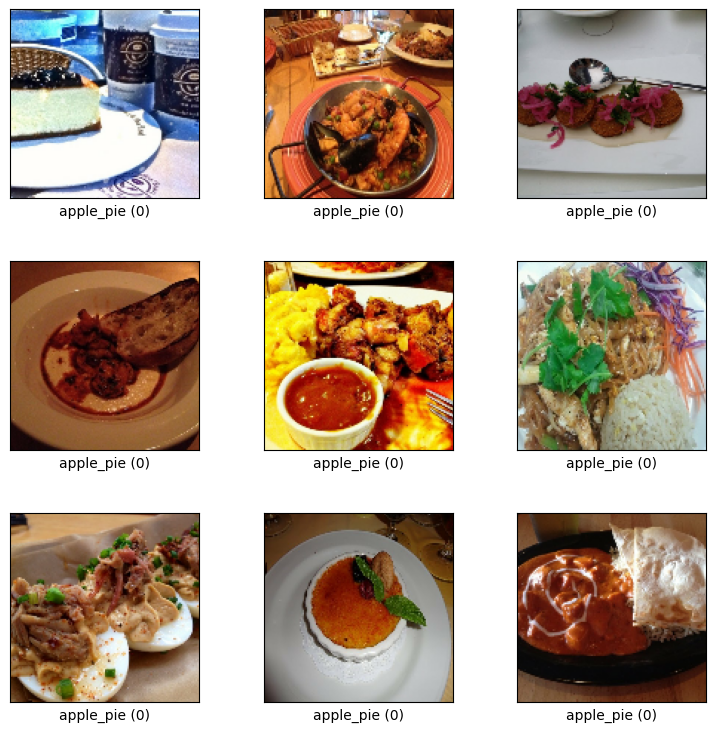

In [ ]:
fig = tfds.show_examples(train_ds,ds_info)

In [ ]:
#reshaping the dataset cause only 750 hotdog images
train_hdog_size , valid_hdog_size = 750 , 250
train_hdogs = train_ds.filter(lambda image, label: label ==1).repeat(3)
train_nothdogs = train_ds.filter(lambda image, label: label ==0)
valid_hdogs = valid_ds.filter(lambda image, label: label ==1).repeat(3)
valid_nothdogs = valid_ds.filter(lambda image, label: label ==0)


In [ ]:
train_ds = tf.data.Dataset.sample_from_datasets([train_hdogs,train_nothdogs],weights=[0.5,0.5],stop_on_empty_dataset=True).batch(16)
train_ds = train_ds.cache().prefetch(tf.data.AUTOTUNE)
valid_ds = tf.data.Dataset.sample_from_datasets([valid_hdogs,valid_nothdogs],weights=[0.5,0.5],stop_on_empty_dataset=True).batch(16)
valid_ds = valid_ds.cache().prefetch(tf.data.AUTOTUNE)

In [ ]:
data_augmentation = tf.keras.Sequential([
  tf.keras.layers.RandomFlip('horizontal'),
  tf.keras.layers.RandomRotation(0.2),
])

In [ ]:
#Neural network
random.seed(42)
model = models.Sequential()
model.add(layers.Rescaling(1./255))
model.add(data_augmentation)
model.add(layers.Conv2D(128,(3,3),activation='relu',input_shape=(max_side,max_side,3)))
model.add(layers.MaxPooling2D((2,2)))
model.add(layers.Dropout(0.25))
model.add(layers.Conv2D(64,(3,3),activation='relu'))
model.add(layers.MaxPooling2D((2,2)))
model.add(layers.Dropout(0.25))
model.add(layers.Conv2D(32,(3,3),activation='relu'))
model.add(layers.Flatten())
model.add(layers.Dense(128,activation='relu'))
model.add(layers.Dropout(0.25))
model.add(layers.Dense(1))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
lr = 0.0001
model.compile(optimizer=tf.keras.optimizers.Adam(lr),
              loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
              metrics=['accuracy'])

In [ ]:
epochs=50
history = model.fit(
  train_ds,
  validation_data=valid_ds,
  epochs=epochs,
  verbose=1
)

Epoch 1/50
    281/Unknown 16s 36ms/step - accuracy: 0.5024 - loss: 0.6992

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


281/281 ━━━━━━━━━━━━━━━━━━━━ 17s 39ms/step - accuracy: 0.4996 - loss: 0.6931 - val_accuracy: 0.5036 - val_loss: 0.6861
Epoch 2/50
281/281 ━━━━━━━━━━━━━━━━━━━━ 10s 37ms/step - accuracy: 0.5283 - loss: 0.6770 - val_accuracy: 0.5136 - val_loss: 0.6680
Epoch 3/50
281/281 ━━━━━━━━━━━━━━━━━━━━ 10s 37ms/step - accuracy: 0.5341 - loss: 0.6731 - val_accuracy: 0.5228 - val_loss: 0.6594
Epoch 4/50
281/281 ━━━━━━━━━━━━━━━━━━━━ 10s 37ms/step - accuracy: 0.5575 - loss: 0.6575 - val_accuracy: 0.5606 - val_loss: 0.6394
Epoch 5/50
281/281 ━━━━━━━━━━━━━━━━━━━━ 10s 37ms/step - accuracy: 0.5942 - loss: 0.6374 - val_accuracy: 0.6009 - val_loss: 0.6233
Epoch 6/50
281/281 ━━━━━━━━━━━━━━━━━━━━ 10s 37ms/step - accuracy: 0.6229 - loss: 0.6202 - val_accuracy: 0.5903 - val_loss: 0.6190
Epoch 7/50
281/281 ━━━━━━━━━━━━━━━━━━━━ 10s 36ms/step - accuracy: 0.6503 - loss: 0.6005 - val_accuracy: 0.6188 - val_loss: 0.5944
Epoch 8/50
281/281 ━━━━━━━━━━━━━━━━━━━━ 10s 37ms/step - accuracy: 0.6610 - loss: 0.5900 - val_accurac

In [ ]:
model.save("hotdog_cnn.keras")